# Sales Performance Analysis for Supermarket  

The objective of this project is to perform exploratory data analysis on supermarket sales data to uncover sales trends, customer behaviour and profitability patterns, and to provide insights that support business decisions.
1. What is the total sales,total gross income,average values.
2. What are the best and the worst products.
3. Which cities had best sales and also which branch.
4. Compare spendings between male and female customers.
5. Check customer satisfaction
6. Find relationships between unit price,quantity,total and gross income
   

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("Supermarket_sales.csv")

In [4]:
df.shape

(1000, 17)

In [5]:
df.head()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
0,750-67-8428,A,Yangon,Member,Female,Health and beauty,74.69,7,26.1415,548.9715,1/5/2019,13:08,Ewallet,522.83,4.761905,26.1415,9.1
1,226-31-3081,C,Naypyitaw,Normal,Female,Electronic accessories,15.28,5,3.8200,80.2200,3/8/2019,10:29,Cash,76.40,4.761905,3.8200,9.6
2,631-41-3108,A,Yangon,Normal,Male,Home and lifestyle,46.33,7,16.2155,340.5255,3/3/2019,13:23,Credit card,324.31,4.761905,16.2155,7.4
3,123-19-1176,A,Yangon,Member,Male,Health and beauty,58.22,8,23.2880,489.0480,1/27/2019,20:33,Ewallet,465.76,4.761905,23.2880,8.4
4,373-73-7910,A,Yangon,Normal,Male,Sports and travel,86.31,7,30.2085,634.3785,2/8/2019,10:37,Ewallet,604.17,4.761905,30.2085,5.3


In [6]:
df.tail()

,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Time,Payment,cogs,gross margin percentage,gross income,Rating
995,233-67-5758,C,Naypyitaw,Normal,Male,Health and beauty,40.35,1,2.0175,42.3675,1/29/2019,13:46,Ewallet,40.35,4.761905,2.0175,6.2
996,303-96-2227,B,Mandalay,Normal,Female,Home and lifestyle,97.38,10,48.6900,1022.4900,3/2/2019,17:16,Ewallet,973.80,4.761905,48.6900,4.4
997,727-02-1313,A,Yangon,Member,Male,Food and beverages,31.84,1,1.5920,33.4320,2/9/2019,13:22,Cash,31.84,4.761905,1.5920,7.7
998,347-56-2442,A,Yangon,Normal,Male,Home and lifestyle,65.82,1,3.2910,69.1110,2/22/2019,15:33,Cash,65.82,4.761905,3.2910,4.1
999,849-09-3807,A,Yangon,Member,Female,Fashion accessories,88.34,7,30.9190,649.2990,2/18/2019,13:28,Cash,618.38,4.761905,30.9190,6.6


In [16]:
df.Date = pd.to_datetime(df.Date) 

In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Invoice ID               1000 non-null   str           
 1   Branch                   1000 non-null   str           
 2   City                     1000 non-null   str           
 3   Customer type            1000 non-null   str           
 4   Gender                   1000 non-null   str           
 5   Product line             1000 non-null   str           
 6   Unit price               1000 non-null   float64       
 7   Quantity                 1000 non-null   int64         
 8   Tax 5%                   1000 non-null   float64       
 9   Total                    1000 non-null   float64       
 10  Date                     1000 non-null   datetime64[us]
 11  Time                     1000 non-null   str           
 12  Payment                  1000 non-null   str  

1. In the given data of supermarket sales their are 1000 rows and 17 columns.
2. There are 9 columns  in "str", 7 in "float" dtype and only 1 i.e, "Quantity" column in "int" dtype and        "Date" column converted to "datetime" dtype.
3. In the observation we can find that non of the column has missing values.

In [18]:
df.describe()

,Unit price,Quantity,Tax 5%,Total,Date,cogs,gross margin percentage,gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.00000
mean,55.672130,5.510000,15.379369,322.966749,2019-02-14 00:05:45.600000,307.58738,4.761905,15.379369,6.97270
min,10.080000,1.000000,0.508500,10.678500,2019-01-01 00:00:00,10.17000,4.761905,0.508500,4.00000
25%,32.875000,3.000000,5.924875,124.422375,2019-01-24 00:00:00,118.49750,4.761905,5.924875,5.50000
50%,55.230000,5.000000,12.088000,253.848000,2019-02-13 00:00:00,241.76000,4.761905,12.088000,7.00000
75%,77.935000,8.000000,22.445250,471.350250,2019-03-08 00:00:00,448.90500,4.761905,22.445250,8.50000
max,99.960000,10.000000,49.650000,1042.650000,2019-03-30 00:00:00,993.00000,4.761905,49.650000,10.00000
std,26.494628,2.923431,11.708825,245.885335,NaN,234.17651,0.000000,11.708825,1.71858


# Key Takeaways:
- Total Sales: Range from minimum 10.68 to maximum 1042.65,
               Average of Total Sales: avg = 322.96
- Quantity: avg = 5.51,
            Range: 1 to 10
- Rating: avg = 6.97,
          Range: 4 to 10
- Unit price: avg price = 55.67,
              min price = 10.08,
              max price = 99.96
- Since the value of mean is little greater than the median the data exibits positive skewness.
- By using the Empirical rule (68-95-99.7) 67% of data lies between 5.25412 to 8.69128 Rating.

In [19]:
df.isnull().sum() 

Invoice ID                 0
Branch                     0
City                       0
Customer type              0
Gender                     0
Product line               0
Unit price                 0
Quantity                   0
Tax 5%                     0
Total                      0
Date                       0
Time                       0
Payment                    0
cogs                       0
gross margin percentage    0
gross income               0
Rating                     0
dtype: int64

- No missing values

In [23]:
df.duplicated().sum()

np.int64(0)

- No duplicate values

## Correlation between all numerical columns 

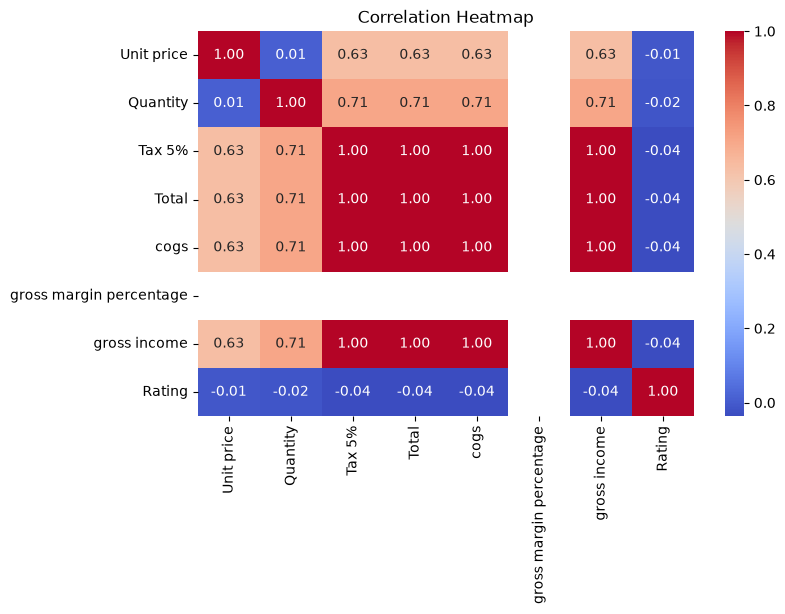

In [37]:
plt.figure(figsize=(8,5))
sns.heatmap(df.select_dtypes(["float64","int64"]).corr(), annot=True, cmap='coolwarm',fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

# Observation
- Gross income and Total sales have a correlation of 1.00. This is beacause grass margin % is constant at 4.76% ,so they are perfectly linear.
- Quantity has a moderate correlation with Total sales,it shows that both price and number of items affects revenue.
- By looking at the customers ratings there is no correlation with sales and profit,which may suggest that customers rate based on the service or product quality rather than value they pay.
    

# Total Sales based on Branch

In [73]:
# as_index = "DataFrame, with Branch as a regular column"-- "You get a clean DataFrame with a default 0, 1, 2 index, ready for sort_values, plotting, or merging."

In [60]:
branch_sales = (df.groupby('Branch',as_index=False).Total.sum().sort_values('Total',ascending=False))
branch_sales

,Branch,Total
2,C,110568.7065
0,A,106200.3705
1,B,106197.6720


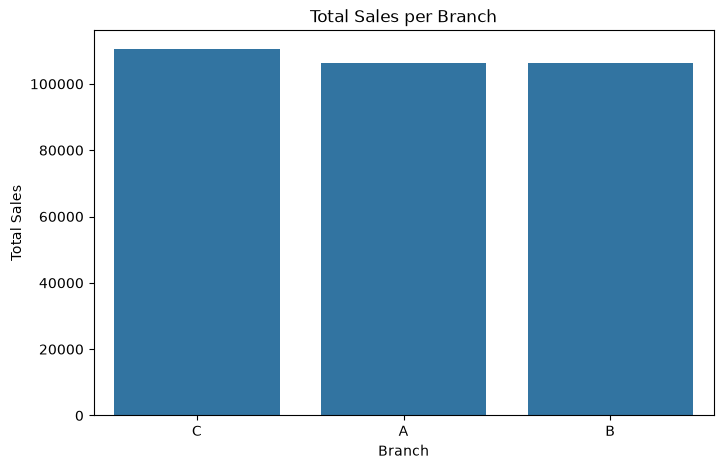

In [65]:
plt.figure(figsize=(8,5))
sns.barplot(x="Branch", y="Total", data = branch_sales)
plt.title("Total Sales per Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales")
plt.show()

# Quantity sold by Product Line

In [70]:
product_sales=df.groupby('Product line',as_index=False).Quantity.sum().sort_values('Quantity',ascending=False)
product_sales

,Product line,Quantity
0,Electronic accessories,971
2,Food and beverages,952
5,Sports and travel,920
4,Home and lifestyle,911
1,Fashion accessories,902
3,Health and beauty,854


([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'Electronic accessories'),
  Text(1, 0, 'Food and beverages'),
  Text(2, 0, 'Sports and travel'),
  Text(3, 0, 'Home and lifestyle'),
  Text(4, 0, 'Fashion accessories'),
  Text(5, 0, 'Health and beauty')])

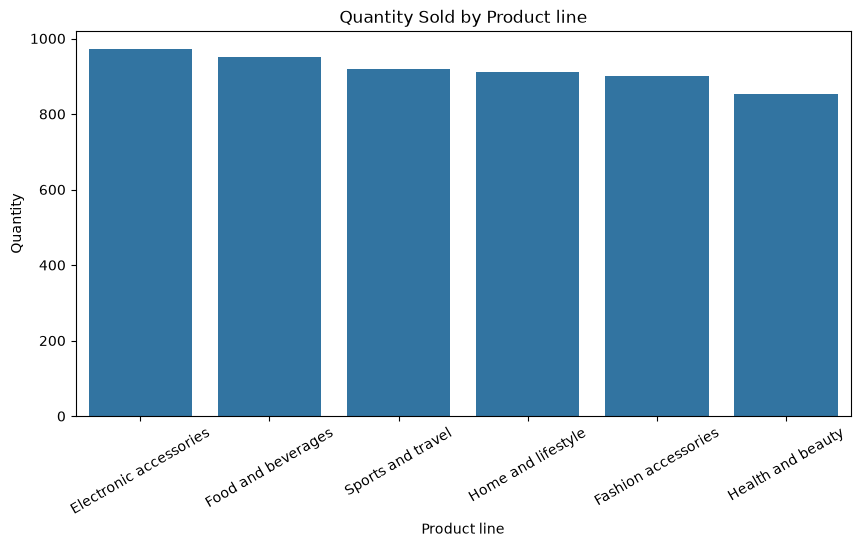

In [72]:
plt.figure(figsize=(10,5))
sns.barplot(x='Product line',y='Quantity',data=product_sales)
plt.title('Quantity Sold by Product line')
plt.xlabel('Product line')
plt.ylabel('Quantity')
plt.xticks(rotation=30)


#  Total Sales by Gender

In [74]:
gender_sales=df.groupby('Gender',as_index=False).Total.sum().sort_values('Total',ascending=False)
gender_sales

,Gender,Total
0,Female,167882.925
1,Male,155083.824


(np.float64(-1.0999990556524195),
 np.float64(1.099992043193236),
 np.float64(-1.099998760236625),
 np.float64(1.0999853486453293))

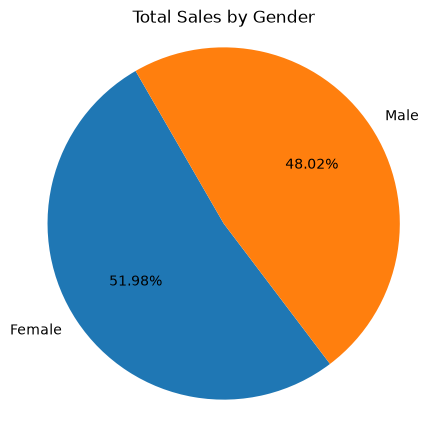

In [83]:
plt.figure(figsize=(5,5))
plt.pie(gender_sales.Total,labels=gender_sales.Gender,autopct='%.2f%%',startangle=120)
plt.title('Total Sales by Gender')
plt.axis('equal')



 # Average Sales by Gender

In [84]:
gender_avg=df.groupby('Gender',as_index=False).Total.mean()
gender_avg

,Gender,Total
0,Female,335.095659
1,Male,310.789226


# Count of each gender

In [107]:
df['Gender'].value_counts()

Gender
Female    501
Male      499
Name: count, dtype: int64

#  Product Line Preference by Gender

In [113]:
gender_product=df.groupby(['Gender','Product line'],as_index=False).Total.sum().sort_values('Total',ascending=False)
gender_product

,Gender,Product line,Total
2,Female,Food and beverages,33170.9175
9,Male,Health and beauty,30632.7525
1,Female,Fashion accessories,30437.4000
4,Female,Home and lifestyle,30036.8775
5,Female,Sports and travel,28574.7210
6,Male,Electronic accessories,27235.5090
0,Female,Electronic accessories,27102.0225
11,Male,Sports and travel,26548.1055
7,Male,Fashion accessories,23868.4950
10,Male,Home and lifestyle,23825.0355


([0, 1, 2, 3, 4, 5],
 [Text(0, 0, 'Food and beverages'),
  Text(1, 0, 'Health and beauty'),
  Text(2, 0, 'Fashion accessories'),
  Text(3, 0, 'Home and lifestyle'),
  Text(4, 0, 'Sports and travel'),
  Text(5, 0, 'Electronic accessories')])

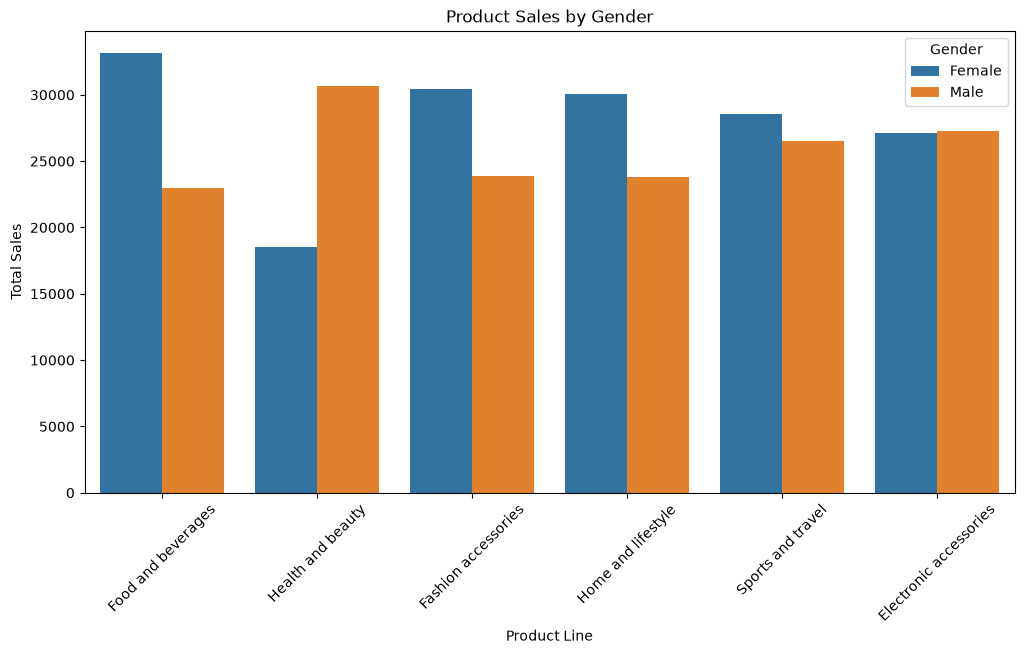

In [114]:
plt.figure(figsize=(12,6))
sns.barplot(x='Product line',y='Total',hue='Gender',data=gender_product)
plt.title('Product Sales by Gender')
plt.xlabel('Product Line')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

- In this chart we can observe that food and beverages is the highest spending category for female customers and for male health and beauty is highest spending category.
- Spending in sports and travel , electronic accessories is nearly equal for both.
- Food and beverages single handedly brings the highest revenue.

In [122]:
df.groupby(['Branch','City'],as_index=False).Total.sum().sort_values('Total',ascending=False)

,Branch,City,Total
2,C,Naypyitaw,110568.7065
0,A,Yangon,106200.3705
1,B,Mandalay,106197.6720


- Here we can see that city sale is exactly equal to the branch sale so we dont need to separate city chart.

# Correlation between 'Unit price', 'Quantity', 'Total', 'gross income' columns.

In [126]:
cols = ['Unit price', 'Quantity', 'Total', 'gross income']
df[cols].corr().round(3)

,Unit price,Quantity,Total,gross income
Unit price,1.000,0.011,0.634,0.634
Quantity,0.011,1.000,0.706,0.706
Total,0.634,0.706,1.000,1.000
gross income,0.634,0.706,1.000,1.000


Text(0.5, 1.0, 'Unit price and Total Relation')

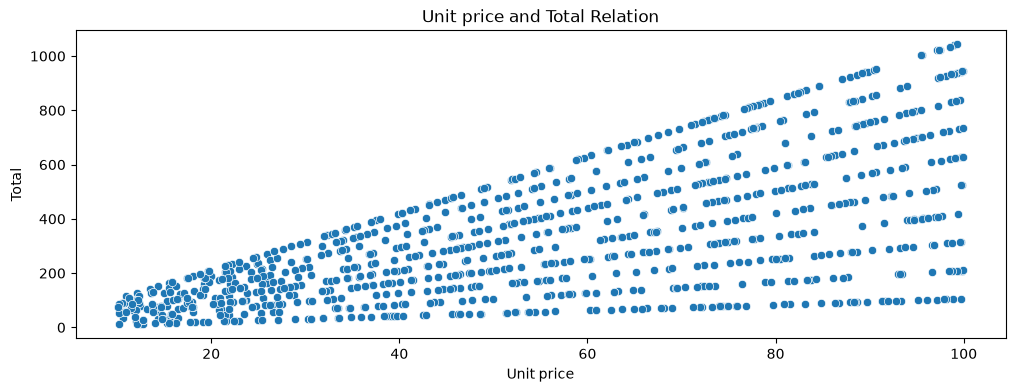

In [130]:
plt.figure(figsize=(12,4))
sns.scatterplot(x='Unit price',y='Total',data=df)
plt.title('Unit price and Total Relation')

- Upward trend is a higher unit price generally means a higher total, which matches the 0.634 correlation.
- At low prices (around 10 to 20) the dots are bunched together, because even 10 units only gives a small total.
- Price alone doesn’t determine the bill.
- The same price can produce very different totals depending on quantity.

Text(0.5, 1.0, 'Quantity and Total Relation')

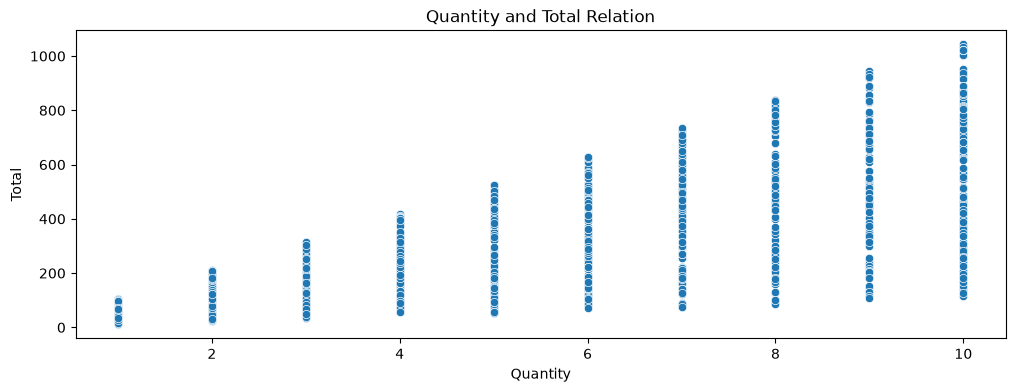

In [131]:
plt.figure(figsize=(12,4))
sns.scatterplot(x='Quantity', y='Total', data=df)
plt.title('Quantity and Total Relation')

- It shows vertical strips as quantity is in whole number.
- As we can see that data is rising the maximum total grows with quantity, from about 100 at 1 unit to about 1,050 at 10 units. This matches the stronger 0.706 correlation.
- As we see that quantity has strong correlation with total but unit price decides which column it should be.


# Conclusion

- This analysis looked at 1,000 supermarket transactions with 17 columns. The data was clean, with no missing or duplicate values.
- Total sales were about 322,967, and the average total was about 323.
- All three branches performed almost equally,Since each branch belongs to one city, the city-wise results are the same as the branch-wise results.
- Customer behaviour showed some clear patterns.Male and Female both are equal in numbers but females contributed about 52% of Total sale.
- Overall, by my analysis to grow the revenue of the supermarket we need encourage customers to buy more items on every visit.
- Give some combo offers and discounts on bulk purchase.
- We can also target each gender based on there preferance.
- Also by advertising the product based on its benefit for customers.
This will help to grow the revenue of the supermarket as per the analysis.